Lab 3

Conor Murray

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import  statsmodels.formula.api as smf
from scipy import stats
from statsmodels.graphics.gofplots import ProbPlot
from statsmodels.stats.outliers_influence import variance_inflation_factor
df = pd.read_csv("Bank_Salaries.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Employee_ID  208 non-null    int64 
 1   Education    208 non-null    int64 
 2   Grade        208 non-null    int64 
 3   Years1       208 non-null    int64 
 4   Years2       208 non-null    int64 
 5   Age          208 non-null    int64 
 6   Gender       208 non-null    object
 7   PC_Job       208 non-null    object
 8   Salary       208 non-null    object
dtypes: int64(6), object(3)
memory usage: 14.8+ KB


In [2]:
df.head(10)

,Employee_ID,Education,Grade,Years1,Years2,Age,Gender,PC_Job,Salary
0,1,3,1,3,1,26,Male,No,"$32,000"
1,2,1,1,14,1,38,Female,No,"$39,100"
2,3,1,1,12,0,35,Female,No,"$33,200"
3,4,2,1,8,7,40,Female,No,"$30,600"
4,5,3,1,3,0,28,Male,No,"$29,000"
5,6,3,1,3,0,24,Female,No,"$30,500"
6,7,3,1,4,0,27,Female,No,"$30,000"
7,8,3,1,8,2,33,Male,No,"$27,000"
8,9,1,1,4,0,62,Female,No,"$34,000"
9,10,3,1,9,0,31,Female,No,"$29,500"


In [3]:
df.describe()

,Employee_ID,Education,Grade,Years1,Years2,Age
count,208.000000,208.000000,208.000000,208.000000,208.000000,208.000000
mean,104.500000,3.158654,2.759615,9.673077,2.375000,40.394231
std,60.188592,1.467464,1.566529,6.987832,3.135237,10.318988
min,1.000000,1.000000,1.000000,2.000000,0.000000,22.000000
25%,52.750000,2.000000,1.000000,5.000000,0.000000,32.000000
50%,104.500000,3.000000,3.000000,8.000000,1.000000,38.500000
75%,156.250000,5.000000,4.000000,13.000000,4.000000,47.250000
max,208.000000,5.000000,6.000000,39.000000,18.000000,65.000000


In [4]:
df['Salary'] = pd.to_numeric(df['Salary'].str.replace('[$,]', '', regex=True))

df['Salary'].head()

0    32000
1    39100
2    33200
3    30600
4    29000
Name: Salary, dtype: int64

In [5]:
df.describe(include='object')

,Gender,PC_Job
count,208,208
unique,2,2
top,Female,No
freq,140,189


In [6]:
print(df['Gender'].value_counts(dropna=False))

Gender
Female    140
Male       68
Name: count, dtype: int64


In [7]:
df.isna().sum()

Employee_ID    0
Education      0
Grade          0
Years1         0
Years2         0
Age            0
Gender         0
PC_Job         0
Salary         0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [10]:
for col in df.select_dtypes(include='number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()  
    print(f"{col:20s} outliers: {n_out}   (bounds {lower:.1f} to {upper:.1f})")

Employee_ID          outliers: 0   (bounds -102.5 to 311.5)
Education            outliers: 0   (bounds -2.5 to 9.5)
Grade                outliers: 0   (bounds -3.5 to 8.5)
Years1               outliers: 7   (bounds -7.0 to 25.0)
Years2               outliers: 3   (bounds -6.0 to 10.0)
Age                  outliers: 0   (bounds 9.1 to 70.1)
Salary               outliers: 8   (bounds 16500.0 to 60500.0)


The simualr variables with outliers are years1 and years2 Since year 2 is already left skewed and the outliers are on the right i would include them. Simular goes for year 1 since it is also left skewed though not as bad. It also has many more outliers that might darastically change the data, I would run the test including and also excluding the outliers to see how the data from the year1 variable compares but the best option would probably be to exclude outliers from years1 and not years2
Salary has the most outliers at 8 and is also an important category of data so I would try to see if there was a reason like false input or recording that led to these outliers as well as how much of an effect they have on the data

In [11]:
df['Gender'] = (df['Gender'] == 'Female').astype(int)
df['PC_Job'] = (df['PC_Job'] == 'Yes').astype(int)
df.head()

,Employee_ID,Education,Grade,Years1,Years2,Age,Gender,PC_Job,Salary
0,1,3,1,3,1,26,0,0,32000
1,2,1,1,14,1,38,1,0,39100
2,3,1,1,12,0,35,1,0,33200
3,4,2,1,8,7,40,1,0,30600
4,5,3,1,3,0,28,0,0,29000


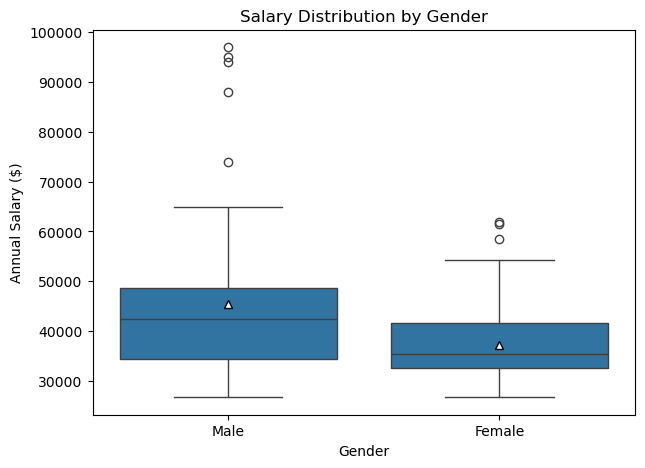

In [12]:
df['Gender_label'] = df['Gender'].map({0: 'Male', 1: 'Female'})

plt.figure(figsize=(7, 5))
sns.boxplot(x='Gender_label', y='Salary', data=df, showmeans=True, meanprops={'marker': '^', 'markerfacecolor': 'white', 'markeredgecolor': 'black'})
plt.title('Salary Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Annual Salary ($)')
plt.show()

In [13]:
female_salary = df[df['Gender'] == 1]['Salary']
male_salary = df[df['Gender'] == 0]['Salary']
print(f"Female: n = {len(female_salary)}, mean = ${female_salary.mean():,.0f}, std = ${female_salary.std():,.0f}")
print(f"Male:   n = {len(male_salary)}, mean = ${male_salary.mean():,.0f}, std = ${male_salary.std():,.0f}")
lev_stat, lev_p = stats.levene(female_salary, male_salary)
print(f"Levene's test p-value = {lev_p:.2e}")

Female: n = 140, mean = $37,210, std = $6,711
Male:   n = 68, mean = $45,505, std = $15,843
Levene's test p-value = 7.01e-07


In [14]:
t_stat, p_value = stats.ttest_ind(female_salary, male_salary, equal_var=False, alternative='less')
print(f"t-statistic = {t_stat:.3f}")
print(f"one-tailed p-value = {p_value:.2e}")
print(f"Raw difference in means (female - male) = ${female_salary.mean() - male_salary.mean():,.0f}")
if p_value < 0.05:
    print("Decision: Reject H0. Female mean salary is significantly lower than male mean salary.")
else:
    print("Decision: Fail to reject H0.")

t-statistic = -4.141
one-tailed p-value = 4.30e-05
Raw difference in means (female - male) = $-8,296
Decision: Reject H0. Female mean salary is significantly lower than male mean salary.


In [15]:
t_eq, p_eq = stats.ttest_ind(female_salary, male_salary, alternative='less')
print(f"Equal-variance version: t = {t_eq:.3f}, one-tailed p = {p_eq:.2e}")

Equal-variance version: t = -5.302, one-tailed p = 1.47e-07


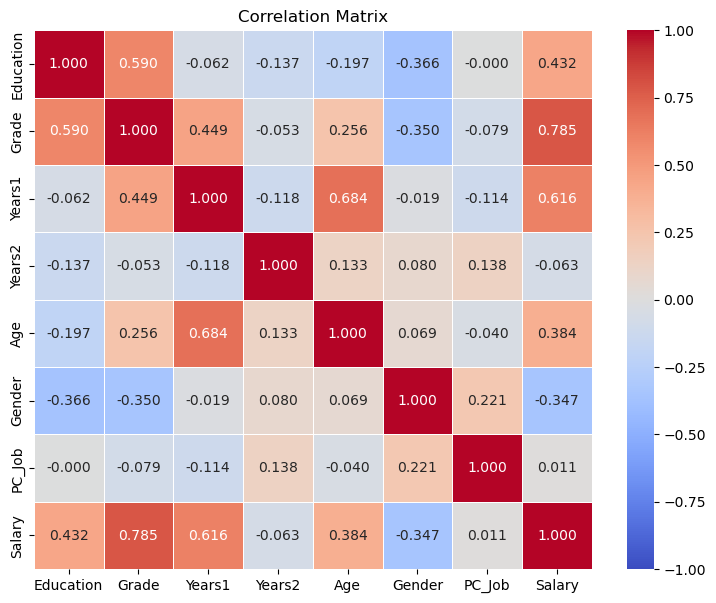

In [16]:
corr_cols = ['Education', 'Grade', 'Years1', 'Years2', 'Age', 'Gender', 'PC_Job', 'Salary']
corr_matrix = df[corr_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".3f", linewidth=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [17]:
print(corr_matrix['Salary'].drop('Salary').sort_values(ascending=False))

Grade        0.785202
Years1       0.615610
Education    0.431910
Age          0.383798
PC_Job       0.010824
Years2      -0.062671
Gender      -0.346541
Name: Salary, dtype: float64


In [18]:
X = sm.add_constant(df[['Education', 'Grade', 'Years1', 'Years2', 'Age', 'Gender', 'PC_Job']])
vif = pd.DataFrame({'Variable': X.columns[1:], 'VIF': [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]})
vif.round(2)

,Variable,VIF
0,Education,2.13
1,Grade,2.57
2,Years1,2.59
3,Years2,1.15
4,Age,2.14
5,Gender,1.27
6,PC_Job,1.09


In [19]:
model1 = smf.ols(formula="Salary ~ Gender", data=df).fit()
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.120
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     28.12
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           2.94e-07
Time:                        14:41:56   Log-Likelihood:                -2221.7
No. Observations:                 208   AIC:                             4447.
Df Residuals:                     206   BIC:                             4454.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4.551e+04   1283.530     35.453      0.000     4.3e+04     4.8e+04
Gender     -8295.5126   1564.493     -5.302      0.000   -1.14e+04   -5211.041
==============================================================================
Omnibus:                      106.281   Durbin-Watson:                   0.631
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              541.694
Skew:                           1.985   Prob(JB):                    2.36e-118
Kurtosis:                       9.837   Cond. No.                         3.26
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [20]:
model2 = smf.ols(formula="Salary ~ Gender + Grade + Years1", data=df).fit()
model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.719
Model:                            OLS   Adj. R-squared:                  0.715
Method:                 Least Squares   F-statistic:                     174.4
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           4.87e-56
Time:                        14:41:56   Log-Likelihood:                -2102.8
No. Observations:                 208   AIC:                             4214.
Df Residuals:                     204   BIC:                             4227.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   2.515e+04   1250.401     20.116      0.000    2.27e+04    2.76e+04
Gender     -3284.5890    960.693     -3.419      0.001   -5178.750   -1390.428
Grade       4158.0557    322.607     12.889      0.000    3521.984    4794.127
Years1       569.1157     67.764      8.398      0.000     435.508     702.724
==============================================================================
Omnibus:                       49.800   Durbin-Watson:                   1.592
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              768.261
Skew:                           0.275   Prob(JB):                    1.49e-167
Kurtosis:                      12.399   Cond. No.                         43.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [21]:
years1_mean = df['Years1'].mean()
df['Years1_c'] = df['Years1'] - years1_mean
print(f"Mean of Years1 = {years1_mean:.2f} years")
model3 = smf.ols(formula="Salary ~ Gender + Grade + Years1_c + Gender:Years1_c", data=df).fit()
model3.summary()

Mean of Years1 = 9.67 years


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.804
Method:                 Least Squares   F-statistic:                     213.9
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           1.31e-71
Time:                        14:41:56   Log-Likelihood:                -2063.2
No. Observations:                 208   AIC:                             4136.
Df Residuals:                     203   BIC:                             4153.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        3.236e+04   1132.849     28.567      0.000    3.01e+04    3.46e+04
Gender          -3829.5545    798.132     -4.798      0.000   -5403.247   -2255.862
Grade            3650.8460    272.421     13.401      0.000    3113.708    4187.984
Years1_c         1051.3630     75.012     14.016      0.000     903.460    1199.266
Gender:Years1_c  -986.1345    101.693     -9.697      0.000   -1186.644    -785.625
==============================================================================
Omnibus:                       19.875   Durbin-Watson:                   1.761
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               75.880
Skew:                           0.104   Prob(JB):                     3.33e-17
Kurtosis:                       5.952   Cond. No.                         29.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

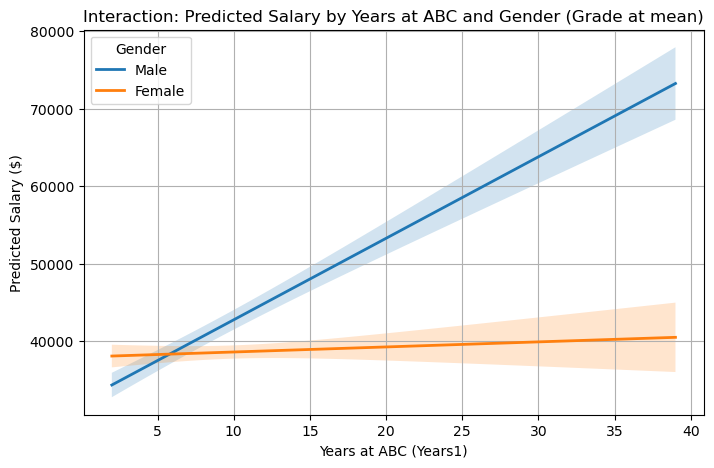

In [22]:
years_range = np.linspace(df['Years1'].min(), df['Years1'].max(), 50)
predict_df = pd.DataFrame([{'Years1': y, 'Gender': g, 'Grade': df['Grade'].mean()}for g in [0, 1] for y in years_range])
predict_df['Years1_c'] = predict_df['Years1'] - years1_mean     
sf = model3.get_prediction(predict_df).summary_frame(alpha=0.05)
predict_df['Salary'] = sf['mean']
predict_df['ci_lower'] = sf['mean_ci_lower']
predict_df['ci_upper'] = sf['mean_ci_upper']
predict_df['Gender_label'] = predict_df['Gender'].map({0: 'Male', 1: 'Female'})

plt.figure(figsize=(8, 5))
sns.lineplot(data=predict_df, x='Years1', y='Salary', hue='Gender_label', linewidth=2)
for g in ['Male', 'Female']:
    sub = predict_df[predict_df['Gender_label'] == g]
    plt.fill_between(sub['Years1'], sub['ci_lower'], sub['ci_upper'], alpha=0.2, linewidth=0, label='_nolegend_')
plt.title('Interaction: Predicted Salary by Years at ABC and Gender (Grade at mean)')
plt.xlabel('Years at ABC (Years1)')
plt.ylabel('Predicted Salary ($)')
plt.legend(title='Gender')
plt.grid(True)
plt.show()

Yes there was a gap in the raw data, male employees earn an average of 45,500 and women earn an average of 37,200 this is a gap of about 8,300.
The visualization shows us a lower female median as well as males being widely distributed compared to females. I added in Grade and Years as they are the two variables that relate the most to salary. 
The gap continued to develop with copntinued experiance with men increasing signfificantly faster than women.


I would have ABC review how raises work for women since their salaries barely grow over the years when compared to the men. I would also have them review promotion criteria for women since with comparable men they tend to be about half a grade lower.

With more access to employees the dataset becomes larger and less prone to errors, specifically more data from seniour employees would give more insight.

Grade is not a specific enough metric. By replacing this with job department, work type, or position title, we could rate jobs based on simularity and difficulty more accurately.